In [1]:
from tf_ofcs import components
from tf_ofcs.plot import plot_phase
from tf_ofcs.datatypes import Signal, Timing

from typing import Any
import tensorflow as tf

2025-05-04 02:02:25.085576: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-05-04 02:02:25.125285: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:9261] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-05-04 02:02:25.125315: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:607] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-05-04 02:02:25.126489: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1515] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-05-04 02:02:25.133101: I external/local_tsl/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-05-04 02:02:25.133818: I tensorflow/core/platform/cpu_feature_guard.cc:1

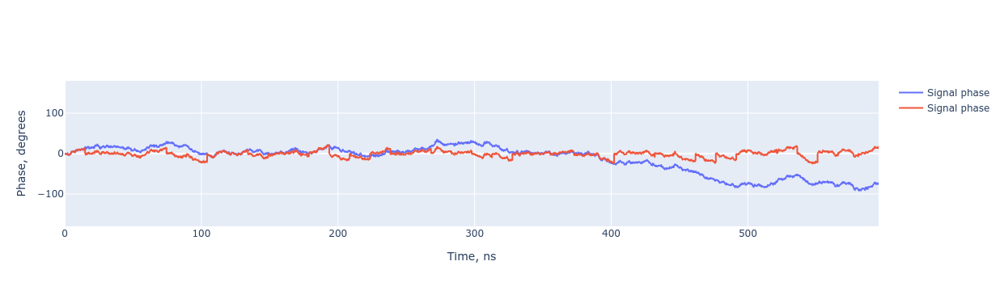

In [10]:
laser = components.Laser(power=[1e-3], linewidth=[0.3e6], enable_phase_noise=True)
pilot_symbol = tf.constant([0.0, 0.0, 0.0, 0.0])
interval = 5000
insert_pilot_symbols = components.InsertPilotSymbols(pilot_symbol, interval)

timing = Timing(sample_count=200000, sampling_rate=336e9)
input_signal = Signal(samples=tf.zeros([1, timing.sample_count], dtype=tf.float32), timing=timing)
signal = insert_pilot_symbols(input_signal)

mzm = components.MachZehnderModulator()
output_signal = mzm((laser(signal), signal))
pilot_aided_phase_recovery = components.PilotAidedPhaseRecovery(tf.complex([0.0, 0.0, 0.0, 0.0], 0.0), interval, keep_pilot_symbols=True)

figure = plot_phase(output_signal)
figure = plot_phase(pilot_aided_phase_recovery(output_signal), figure)
figure